# Can we predict a pass outcome?

This notebook compares Logistic Regression and a Decision Tree Classifier. The data is made up for practice; it is not a record of real students. We'll train both models on the same split, look at accuracy, and then check what their mistakes look like.

## 1. Load the data

The CSV has four input features and an outcome column. `1` means pass; `0` means needs support. `student_id` is just an identifier, so we won't use it as a model input.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

DATA_PATH = Path("data/student_outcomes.csv")
RESULTS_PATH = Path("results")
RESULTS_PATH.mkdir(exist_ok=True)

students = pd.read_csv(DATA_PATH)
students.head()

,student_id,study_hours_per_week,attendance_percent,previous_assessment_score,assignments_completed_percent,outcome
0,1,2,89,76,61,1
1,2,2,85,44,36,0
2,3,15,88,80,85,1
3,4,17,72,65,56,1
4,5,16,82,58,88,1


In [2]:
print(f"Rows and columns: {students.shape}")
print(f"Missing values: {students.isna().sum().sum()}")
print("Outcome counts (0 = needs support, 1 = pass):")
display(students["outcome"].value_counts().sort_index())

Rows and columns: (320, 6)
Missing values: 0
Outcome counts (0 = needs support, 1 = pass):


outcome
0    115
1    205
Name: count, dtype: int64

## 2. Make one train/test split

The test set is held back until evaluation. Stratifying keeps the pass/support proportions similar in both sets. Both models below get these exact same rows.

In [3]:
features = [
    "study_hours_per_week",
    "attendance_percent",
    "previous_assessment_score",
    "assignments_completed_percent",
]
X = students[features]
y = students["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Training rows: {len(X_train)}; test rows: {len(X_test)}")

Training rows: 240; test rows: 80


## 3. Train the classifiers

Logistic Regression benefits from scaling because its inputs are on different ranges. The decision tree uses the original values and has a depth limit so it stays fairly small.

In [4]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

print("Both models have been trained on the same training rows.")

Both models have been trained on the same training rows.


## 4. Compare test results

Accuracy is the share of test predictions that were right. The confusion matrices show the actual and predicted class counts; the label order is **needs support, pass**.

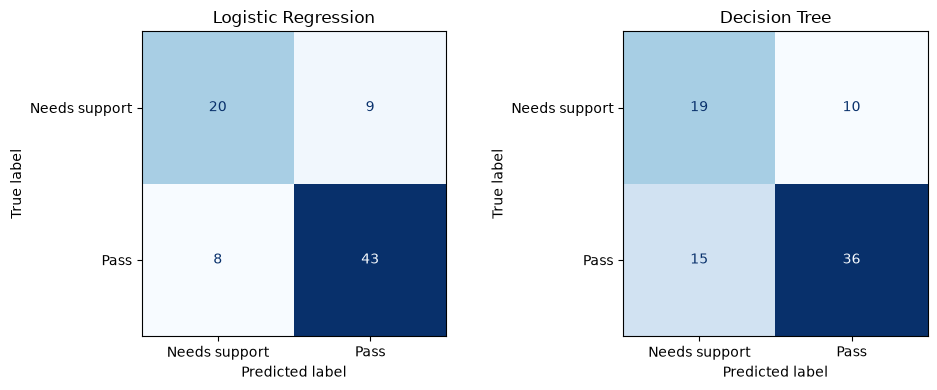

,model,accuracy
0,Logistic Regression,0.7875
1,Decision Tree,0.6875


Saved model_metrics.csv and confusion_matrices.csv in results/.


In [5]:
class_names = ["Needs support", "Pass"]
metric_rows = []
confusion_rows = []

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for (name, model), ax in zip(models.items(), axes):
    y_pred = predictions[name]
    matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
    accuracy = accuracy_score(y_test, y_pred)
    metric_rows.append({"model": name, "accuracy": accuracy})
    for actual_index, actual_label in enumerate(class_names):
        for predicted_index, predicted_label in enumerate(class_names):
            confusion_rows.append({
                "model": name,
                "actual": actual_label,
                "predicted": predicted_label,
                "count": int(matrix[actual_index, predicted_index]),
            })
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

metrics = pd.DataFrame(metric_rows).sort_values("accuracy", ascending=False)
confusion_data = pd.DataFrame(confusion_rows)
display(metrics)
metrics.to_csv(RESULTS_PATH / "model_metrics.csv", index=False)
confusion_data.to_csv(RESULTS_PATH / "confusion_matrices.csv", index=False)
print("Saved model_metrics.csv and confusion_matrices.csv in results/.")

## 5. What kinds of mistakes did they make?

With pass (`1`) as the positive class, a false negative is a student who passed but was predicted to need support. A false positive is a student who needed support but was predicted to pass. The table uses plain-language labels so the two cases are easy to tell apart.

In [6]:
error_rows = []
for name, y_pred in predictions.items():
    actual = y_test.to_numpy()
    predicted = y_pred
    error_rows.append({
        "model": name,
        "needs support predicted pass": int(((actual == 0) & (predicted == 1)).sum()),
        "pass predicted needs support": int(((actual == 1) & (predicted == 0)).sum()),
    })

errors = pd.DataFrame(error_rows)
display(errors)
best_model = metrics.iloc[0]["model"]
print(f"Higher accuracy on this test split: {best_model}")
print("Accuracy alone does not show which mistake type is more common or more important.")

,model,needs support predicted pass,pass predicted needs support
0,Logistic Regression,9,8
1,Decision Tree,10,15


Higher accuracy on this test split: Logistic Regression
Accuracy alone does not show which mistake type is more common or more important.


## Short model card

**Purpose:** A classroom example comparing two binary classifiers. It is not a student assessment tool.

**Data:** 320 synthetic rows with study hours, attendance, a previous assessment score, and assignment completion. The target is a simplified pass/support label. No real student data is included.

**Results:** The accuracy table and confusion matrices above report results on one stratified test split. The higher-accuracy model did better overall on this split, but the error counts matter too; neither result should be treated as evidence about real students.

**Limitations:** The dataset is small, simulated, and based on simple assumptions. It does not represent actual school settings or student differences. The models have not been tested for fairness or reliability. Do not use them to label students or make decisions about support.